In [1]:
import sys
from pathlib import Path
if Path(sys.executable).resolve() != Path('E:\\Temp\\lastfm-windows-acceptance-20261107\\.venv\\Scripts\\python.exe').resolve():
    raise RuntimeError('Wrong Python kernel')

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / 'src'))
import musicrec.final_evaluation as _acceptance_final
def _reject_final_test_scoring(*args, **kwargs):
    raise RuntimeError('Held-out test scoring is disabled during acceptance')
_acceptance_final.run_final_once = _reject_final_test_scoring
_acceptance_final.evaluate = _reject_final_test_scoring
print('Acceptance guard installed for final test scoring')


Acceptance guard installed for final test scoring


# 三个后续模型：真实验证与失败分析

阶段二已实现 BPR-MF、NeuMF、内容双塔。Notebook 默认**重新评分随包真实训练权重**，不会冒称重新训练；设 RETRAIN_ALL=True 可重新训练全部网格与重复种子。训练代码与原始结果均随包提供。

此页保留阶段二开发时的记录。随后已另行冻结并完成独立测试，最新结果见03_frozen_final_test.ipynb；本页的测试封存表述是历史开发状态。

本页重放阶段二验证实验，历史训练环境见 protocol.json。历史随包输出来自 IPython 进程内执行，当前 Windows 原生内核验收结果见 outputs/windows_native_verification/status.json。AI 辅助实现和解释，人工学习/验证/贡献必须如实补充。

In [3]:
from pathlib import Path
import sys,json
import pandas as pd
import torch
from IPython.display import display,Image
ROOT=Path.cwd().resolve()
if not (ROOT/'src/musicrec').is_dir(): ROOT=ROOT.parent
if not (ROOT/'src/musicrec').is_dir(): raise RuntimeError('Project root not found')
sys.path.insert(0,str(ROOT/'src'));sys.path.insert(0,str(ROOT/'scripts'))
from musicrec.phase2 import run_phase2
from replay_phase2 import replay
from summarize_phase2 import summarize
print('Python:',sys.version)
print('PyTorch:',torch.__version__)
print('CPU only; no test evaluation')

Python: 3.12.13 (main, Jun  2 2026, 22:47:20) [MSC v.1944 64 bit (AMD64)]
PyTorch: 2.9.1+cpu
CPU only; no test evaluation


## 1. 全部训练与快速复核是两个明确模式

默认读取已经真实完成的12次训练记录：每族2个学习率、seed42调参，选中学习率再用43/44训练。后面会从权重重新计算9次选中配置的验证指标。想从头复现训练，把下格改为True；会覆盖派生结果，耗时取决于CPU。

In [4]:
RETRAIN_ALL=False
if RETRAIN_ALL:
    runs=run_phase2(ROOT,repeat_seeds=True,max_epochs=24,every=4)
else:
    if not (ROOT/'outputs/phase2/status.json').is_file(): raise RuntimeError('没有已完成结果，请在独立实验副本训练')
    runs=pd.read_csv(ROOT/'outputs/phase2/all_runs.csv')
    print('此格没有重新训练，读取已保存的真实训练记录。下一节会独立重新评分。')
display(runs[['family','lr','seed','selected_epoch','ndcg@10','recall@10','training_seconds','scoring_seconds']].round(6))

此格没有重新训练，读取已保存的真实训练记录。下一节会独立重新评分。


,family,lr,seed,selected_epoch,ndcg@10,recall@10,training_seconds,scoring_seconds
0,bpr_mf,0.005,42,4,0.081823,0.088350,2.479928,0.114940
1,bpr_mf,0.010,42,4,0.080823,0.087285,2.393600,0.124058
2,neumf,0.001,42,4,0.054268,0.066090,4.578353,3.936203
3,neumf,0.003,42,20,0.081037,0.089069,7.166619,4.080723
4,content_two_tower,0.001,42,16,0.100116,0.116525,19.181394,0.141997
5,content_two_tower,0.003,42,12,0.103220,0.113870,19.234939,0.131775
6,bpr_mf,0.005,43,8,0.078669,0.082889,3.001168,0.117828
7,bpr_mf,0.005,44,4,0.079097,0.083671,2.313375,0.111303
8,neumf,0.003,43,24,0.079634,0.089505,7.031178,4.064084
9,neumf,0.003,44,24,0.084718,0.094397,6.700664,4.064921


## 2. 为什么是三个实质不同的模型

- BPR-MF：用户和艺人低秩向量的点积，直接优化正例分数高于采样负例。
- NeuMF：分开的 GMF 与 MLP embedding；前者逐维相乘，后者非线性变换拼接向量，最后融合输出 logit。不是仅给 MF 换损失。
- 内容双塔：独立用户编码与标签内容编码，以归一化向量点积检索。艺人塔没有 artistID embedding，而是训练允许标签的稀疏线性映射加非线性。

损失、学习率、正则、epoch与选择规则见实际配置。改变损失/特征与结构同时发生，所以不能把任何差异归因于某一个因素。

In [5]:
protocol=json.loads((ROOT/'outputs/phase2/protocol.json').read_text(encoding="utf-8"))
display(pd.Series(protocol,name='recorded_protocol'))
content=json.loads((ROOT/'outputs/phase2/content_audit.json').read_text(encoding="utf-8"))
display(pd.Series(content,name='training_only_content_audit'))

grid                          [{'family': 'bpr_mf', 'dim': 32, 'lr': 0.005},...
tuning_seed                                                                  42
repeat_seeds                                                           [43, 44]
max_epochs                                                                   24
validation_every                                                              4
patience_evaluations                                                          3
selection                     macro validation NDCG@10; minimum improvement ...
optimizer                                Adam with coupled L2 weight_decay=1e-4
batch_size                                                                 1024
negative_sampling             one uniform train-warm artist absent from user...
cold_score                    strictly below minimum warm model score; retai...
device                                                                      cpu
threads                                 

raw_tag_events                                                                186479
outside_catalogue_events                                                        1538
within_catalogue_events                                                       184941
allowed_unique_train_tag_events                                                59140
kept_train_tag_events                                                          52884
vocabulary_size                                                                 2000
artists_with_content                                                            5628
artists_without_content                                                        12004
training_artists                                                               15422
min_df                                                                             2
max_features                                                                    2000
max_tags_per_artist                                              

## 3. 防泄漏与内容局限

只有训练 user–artist 对的标签可进入特征；词表、df、IDF全由训练数据确定。用数值tagID，不猜测文本编码。训练目标不通过用户历史池化进入用户塔，因为用户塔只读取ID。

约三分之一目录有合法内容；缺失内容艺人共享unknown特征，不能互相区分。所有验证冷艺人缺内容，因此此模型不能宣称解决新艺人冷启动。标签日期不是听歌时间，本项目没有时序预测结论。

## 4. 五模型的同协议比较

后续模型只汇总选中学习率的seed42/43/44，每个种子都用验证选择停止点。标准差不是独立测试置信区间，也不是固定epoch的纯初始化方差。基线是确定性算法，显示一个数值。

            model  ndcg@10  recall@10  catalogue_coverage@10  seeds
       popularity 0.057249   0.065424               0.001531      1
  itemcf_n100_s10 0.144629   0.151971               0.047868      1
           bpr_mf 0.079863   0.084970               0.005010      3
            neumf 0.081797   0.090990               0.009056      3
content_two_tower 0.103142   0.115675               0.067396      3


,model,ndcg@10,ndcg@10_seed_sd,recall@10,catalogue_coverage@10,seeds
0,popularity,0.057249,NaN,0.065424,0.001531,1
1,itemcf_n100_s10,0.144629,NaN,0.151971,0.047868,1
2,bpr_mf,0.079863,0.001711,0.084970,0.005010,3
3,neumf,0.081797,0.002626,0.090990,0.009056,3
4,content_two_tower,0.103142,0.003416,0.115675,0.067396,3


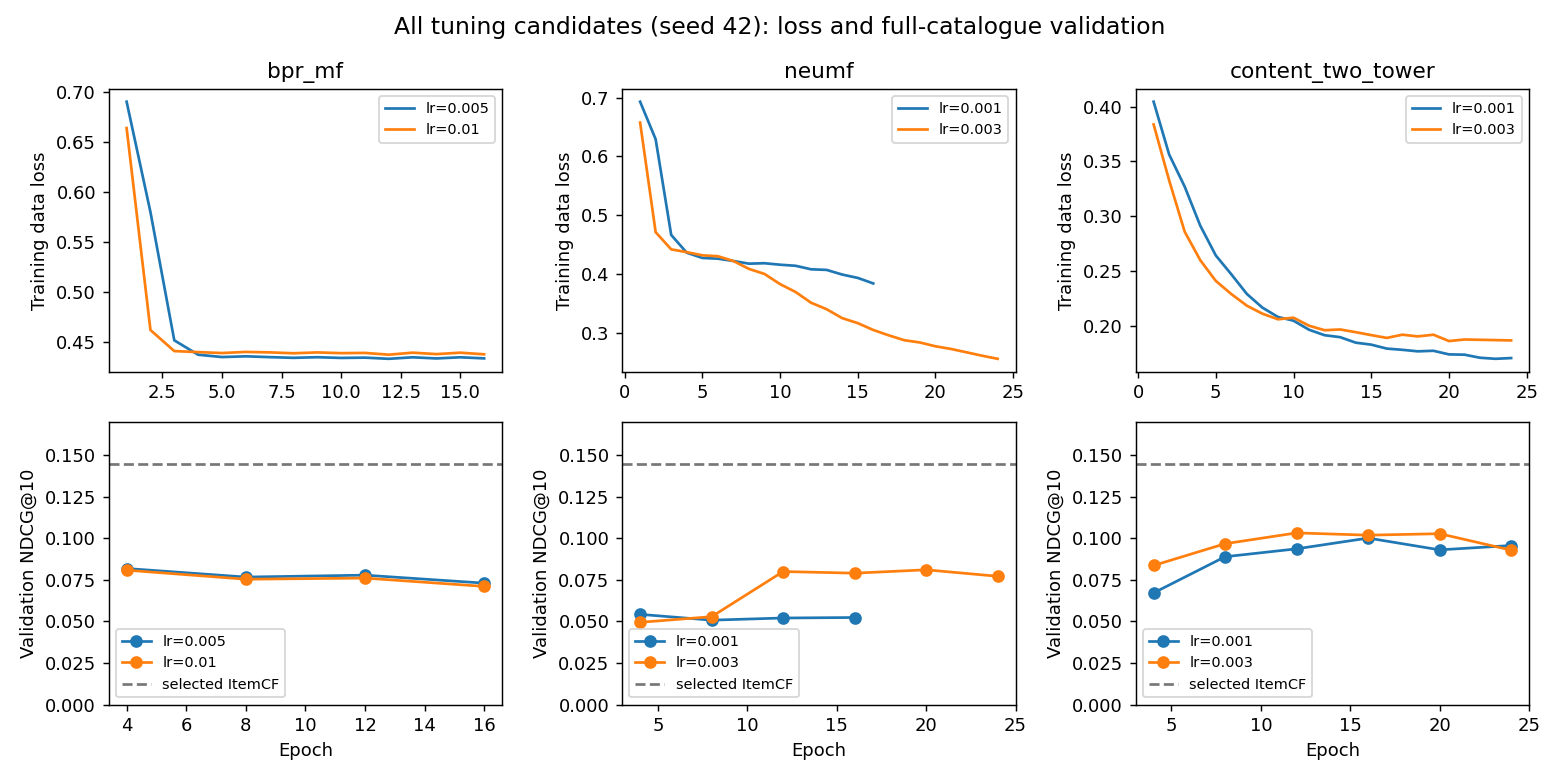

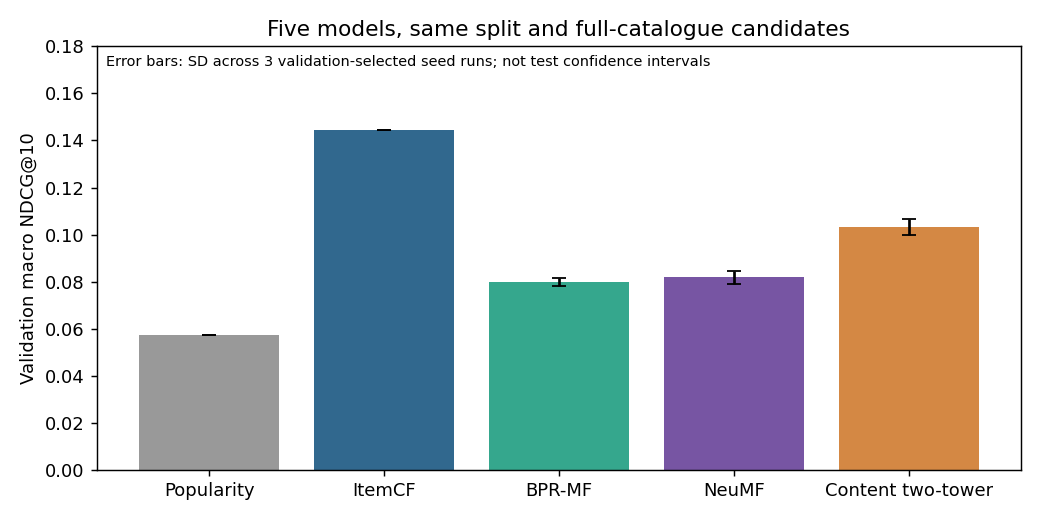

In [6]:
comparison=summarize(ROOT)
display(comparison[['model','ndcg@10','ndcg@10_seed_sd','recall@10','catalogue_coverage@10','seeds']].round(6))
for name in ['04_learning_curves.png','05_validation_comparison.png']:
    display(Image(filename=str(ROOT/'outputs/figures'/name)))

## 5. 从真实权重重新评分，而非只读表

下格重新构建训练特征、读取安全NPZ参数、按全部验证用户与全目录候选重新排名。核对9个选中配置checkpoint的NDCG、Recall、Precision和覆盖率，误差超过1e−7则报错。没有读取test.csv。

In [7]:
replay_checks=replay(ROOT)
display(replay_checks)
if not replay_checks.passed.all(): raise RuntimeError('Checkpoint replay failed')

Replayed: bpr_mf_lr0.005_seed42 NDCG@10=0.081823


Replayed: bpr_mf_lr0.005_seed43 NDCG@10=0.078669


Replayed: bpr_mf_lr0.005_seed44 NDCG@10=0.079097


Replayed: neumf_lr0.003_seed42 NDCG@10=0.081037


Replayed: neumf_lr0.003_seed43 NDCG@10=0.079634


Replayed: neumf_lr0.003_seed44 NDCG@10=0.084718


Replayed: content_two_tower_lr0.003_seed42 NDCG@10=0.103220


Replayed: content_two_tower_lr0.003_seed43 NDCG@10=0.106519


Replayed: content_two_tower_lr0.003_seed44 NDCG@10=0.099688


,run,max_abs_metric_error,ndcg@10,passed
0,bpr_mf_lr0.005_seed42,4.857226e-17,0.081823,True
1,bpr_mf_lr0.005_seed43,9.194034e-17,0.078669,True
2,bpr_mf_lr0.005_seed44,8.326673e-17,0.079097,True
3,neumf_lr0.003_seed42,6.938894e-17,0.081037,True
4,neumf_lr0.003_seed43,6.071532e-17,0.079634,True
5,neumf_lr0.003_seed44,8.326673e-17,0.084718,True
6,content_two_tower_lr0.003_seed42,9.020562e-17,0.103220,True
7,content_two_tower_lr0.003_seed43,6.938894e-17,0.106519,True
8,content_two_tower_lr0.003_seed44,9.020562e-17,0.099688,True


## 6. 分组与成本

有冷目标用户的分组指标不是“只对冷艺人计算的召回率”。低活跃组样本少，不扩大解释。CPU训练耗时、完整评分耗时和验证搜索耗时是不同概念；这里记录的Linux秒数不是Windows性能承诺。

In [8]:
groups=pd.read_csv(ROOT/'outputs/phase2/selected_user_groups.csv')
display(groups.groupby(['model','group'])[['ndcg@10','recall@10']].mean().round(6))
display(pd.read_csv(ROOT/'outputs/phase2/selected_seed_summary.csv')[['model','parameters','mean_training_seconds','mean_scoring_seconds','mean_search_seconds']].round(3))
print('测试指标仍未计算。')

ndcg@10  recall@10
model             group                                     
bpr_mf            all                    0.079863   0.084970
                  all_targets_warm       0.106531   0.113149
                  has_cold_target        0.038428   0.041187
                  train_degree_below_30  0.010554   0.033333
content_two_tower all                    0.103142   0.115675
                  all_targets_warm       0.134916   0.151245
                  has_cold_target        0.053774   0.060408
                  train_degree_below_30  0.033048   0.062963
neumf             all                    0.081797   0.090990
                  all_targets_warm       0.108525   0.120943
                  has_cold_target        0.040268   0.044452
                  train_degree_below_30  0.013066   0.033333

,model,parameters,mean_training_seconds,mean_scoring_seconds,mean_search_seconds
0,bpr_mf,624768,2.598,0.115,22.941
1,neumf,626385,6.966,4.070,62.328
2,content_two_tower,194880,17.801,0.139,36.369


测试指标仍未计算。


## 7. 检查实现，而不是只信曲线

测试覆盖训练对标签过滤、词表门槛、unknown内容、两塔可分解性、NeuMF独立分支梯度、BPR公式、负例采样、冷分数、checkpoint同种子复现及阶段一全部指标协议。

In [9]:
import subprocess
test=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=ROOT,capture_output=True,text=True)
print(test.stdout+test.stderr)
test.check_returncode()

content_two_tower_audit_lr0.003_seed42 epoch 01: loss=0.78370, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 02: loss=0.56224, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 01: loss=0.78370, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 02: loss=0.56224, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 04: loss=0.35957, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 08: loss=0.15370, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 12: loss=0.01681, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 16: loss=0.00026, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed43 epoch 04: loss=0.29278, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed43 epoch 0

## 8. 如何写真实的迭代结论

把“提出假设”和“证据支持”分开：低秩/非线性/内容表示有理论动机，不代表一定超过强邻域基线。当前有限预算下如ItemCF仍领先，应如实保留它，而不是为了最后一个模型好看而改测试规则。

改进方向应先诊断训练目标与Top-K的差距、正则和负采样的敏感性、内容覆盖及过拟合，不从一次失败断言模型家族无效。进一步调参属于内部优化，不新增模型计数。

本页保留阶段二验证实验的范围。已完成的冻结决策与独立测试见第三本 Notebook；Windows 运行证据见独立验收记录。成员需理解方法、填写真实贡献与AI披露。详见 docs/phase2_findings.md、phase2_method.md。